# Week 1 · What is an information system?

Software is only one part of an information system. This week you meet the people, see the whole system working, and write your first lines of Python.

| | |
|---|---|
| **This week's question** | What is an information system, and who depends on it? |
| **Python you will learn** | values, names, types, arithmetic, text, `print`, f-strings |
| **Principle 1** | **Clear names and units.** Code is read by people. A name should say what a value means and in what unit. |
| **Part you build** | the one-line offer summary that the coordinator reads |

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

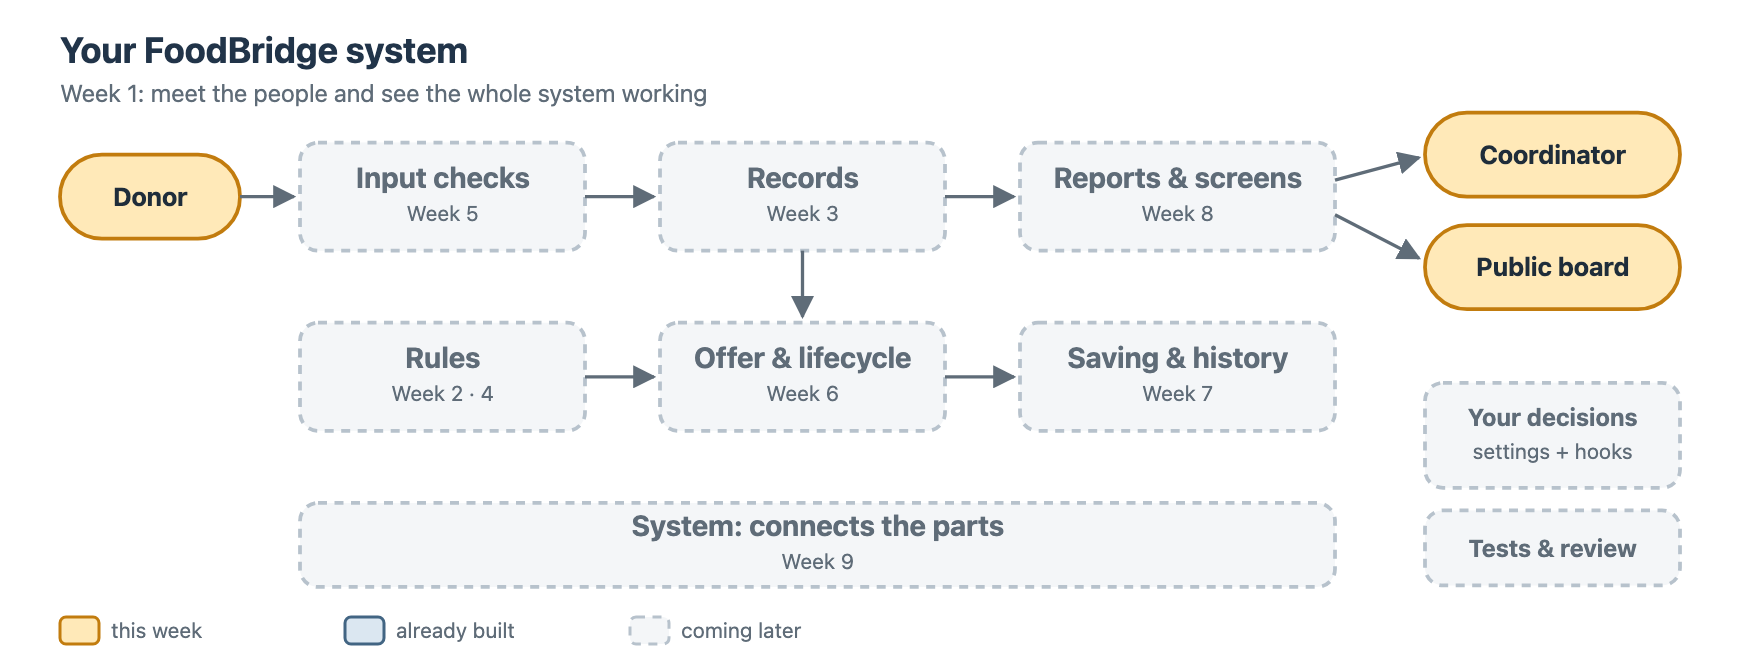

### The story so far

This is where the story starts. Campus FoodBridge helps food shops near campus pass spare food to people who need it, instead of throwing it away. One person — the coordinator — takes the phone calls and writes every offer in a paper notebook: donor, food, portions, and how soon it must be collected.

It is 7:30 on a busy morning. Sunrise Bakery calls: 30 portions of bread rolls. While the coordinator is still writing, a second shop calls, then a third. One number is crossed out and written again. Another is squeezed into the margin. By 8:00, nobody can say which portions belong to which donor — or whether the bread rolls are 30 portions or 80.

Paper cannot keep names and units clear. A system has to **show** every offer in one line that says exactly what each number means. That is this week's work.

### Warm-up · A busy morning

No code yet. Think about the paper notebook in the scene above. The coordinator answers three phone calls in ten minutes and writes each offer by hand.

🤔 **Predict:** what goes wrong **first**? Write one sentence before you look at the answer.

**My answer:** …

<details><summary>Show a possible answer</summary>

There is no single right answer. Most mornings, the first failure is a **number with no clear owner**: a corrected figure is written over the old one, or a new offer is squeezed in without its donor's name, so later nobody knows which shop the portions belong to. A number without a unit fails the same way — "30" alone does not say 30 *what*. This week you fix both problems: clear names, and units in every line.

</details>

## Before you start

1. **Save your own copy first.** In Colab click **Copy to Drive** (or choose **File → Save a copy in Drive**). Work in that copy, not in this original.
2. **Run the setup cell below** (click ▶). Run it again whenever Colab says the runtime restarted.
3. Work from top to bottom. Each section says how long it should take.

Levels: **⭐ core** is for everyone. **⭐⭐ stretch** is optional, for when you finish early.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.7"
_KIT_SHA = "6cbc4e93859ae41969f7dc55dfcb034f96e7b6ecbe5b22070fdb40497e6251ea"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


## Start with the destination (15 min)

By Week 10 you will have built every part of a small information system and made your own decisions about it. Let us see the finished system first. Run the next cell. It replays one fictional day.

In [ ]:
system = bridge.System()
system.run_day()

Read the output slowly. Food was **offered**, some offers were **refused at the door**, a coordinator **approved** or **rejected** offers, and volunteers **picked up** and **delivered** food.

Now look at what two different people see.

In [ ]:
print(system.report("coordinator"))

In [ ]:
print(system.report("public"))

### An information system is more than code

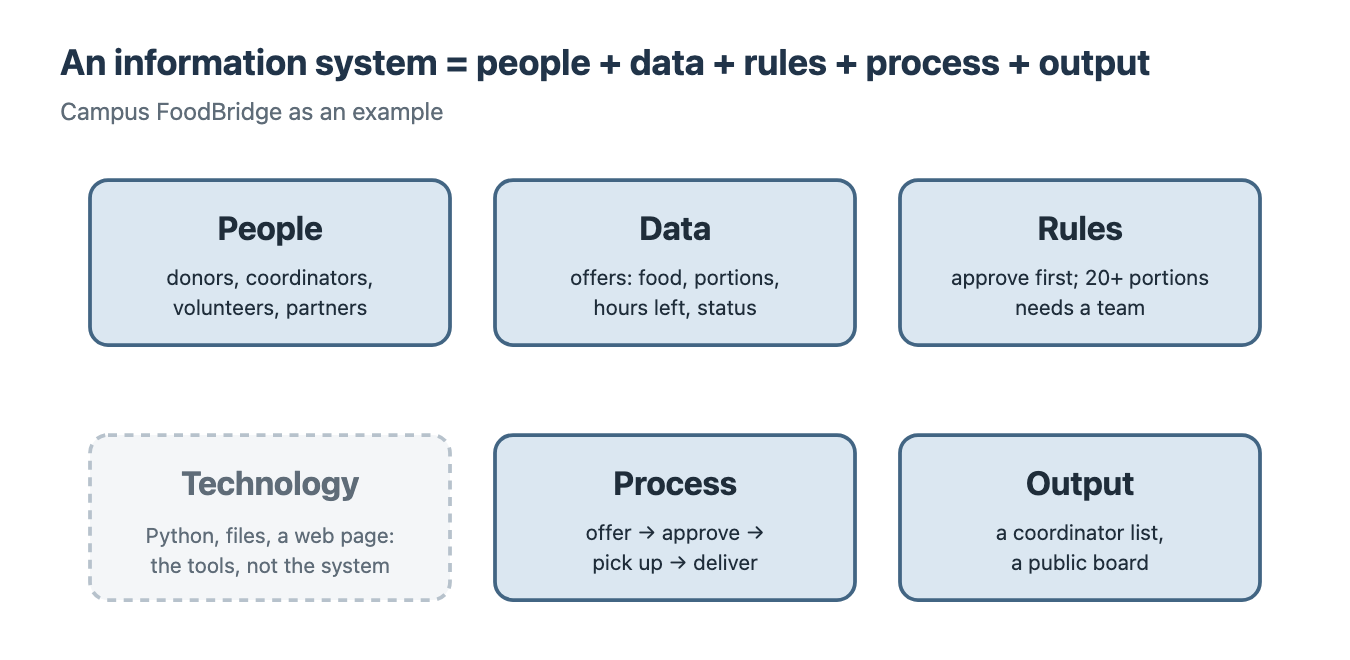

An **information system** is people, data, rules and a process working together to produce useful output. Technology (Python, files, a web page) is the tool. The system is only good if it helps the people.

🤔 **Look back at the outputs above and write short answers.**

1. Name three different **people** (roles) in this system.
2. Name three pieces of **data** the system keeps about an offer.
3. Find one **rule** the system followed. (Hint: why was an offer refused?)
4. Why does the public board show fewer columns than the coordinator view?

📝 **My notes:**

1. People:
2. Data:
3. A rule:
4. Why fewer columns:

## Session 1 · Learn: values, names and text (30 min)

Every program works with **values**: numbers, text, and true/false. Python keeps each value with a **type**, and the type decides what you can do with it.

### 1 · Values and types

In [ ]:
print(30)
print(2.5)
print("Bread rolls")
print(True)
print(type(30), type(2.5), type("Bread rolls"), type(True))

- `int` is a whole number, `float` is a number with a decimal point, `str` is text, `bool` is `True` or `False`.
- Text always has quotes. `"30"` is text that looks like a number; `30` is a number.

We can print values and see their types. The next problem: a value we cannot keep is soon lost, so we give it a name.

### 2 · Names (variables)

A **name** points to a value. `=` means *"let this name point to this value"*. It is not the `=` of mathematics.

In [ ]:
portions = 30
hours_left = 5
food = "Bread rolls"
print(food, portions, hours_left)

You can point a name at a new value. The old value is forgotten.

🤔 **Predict** what the cell prints, then run it.

In [ ]:
portions = 30
portions = portions + 12
print(portions)

**Prediction:** …  **Result:** …  **Why:** …

We can name values and point a name at a new value. The next problem: the coordinator must calculate with those values — share portions out and find what is left over.

### 3 · Arithmetic

| Operator | Meaning | `30 ? 4` |
|---|---|---|
| `+` `-` `*` | add, subtract, multiply | `34`, `26`, `120` |
| `/` | divide (always gives a float) | `7.5` |
| `//` | whole-number division | `7` |
| `%` | remainder | `2` |

In [ ]:
portions = 30
volunteers = 4
print(portions / volunteers)
print(portions // volunteers)
print(portions % volunteers)

🤔 A volunteer cannot carry half a portion. Which of the three answers is useful to the coordinator, and which is misleading? Write one sentence.

**My answer:** …

We can calculate with numbers. The next problem: a phone message arrives as text, and text and numbers refuse to mix.

### 4 · Text and numbers do not mix by accident

`+` adds numbers but **joins** text. Python refuses to join text and a number, because it cannot guess what you mean.

In [ ]:
print(3 + 4)
print("3" + "4")
print(int("30") + 4)      # int() turns text into a whole number
print("Portions: " + str(30))   # str() turns a number into text

We can turn a number into text with `str()`. The next problem: joining many values that way makes a long line that is hard to read.

### 5 · f-strings: text with values inside

Put `f` before the quotes and write names inside `{ }`. Python fills in the values.

In [ ]:
food = "Bread rolls"
portions = 30
hours_left = 5
print(f"{food}: {portions} portions, {hours_left} hours left")

We can build a clear line with an f-string. The next problem: cells run in order, and when something goes wrong we have to read the error.

### 6 · Order matters, and error messages help

Python runs a cell from top to bottom. In a notebook it also remembers names from cells you ran before, **in the order you ran them**. If something looks strange, use **Runtime → Restart session and run all** (Colab) or **Kernel → Restart & Run All** (Jupyter).

When Python cannot continue it shows an **error**. Read the **last line** first: it names the problem.

Remove the `#` at the start of the second line and run the cell. Read the error, then put the `#` back so that *Run all* still works.

In [ ]:
print("This line runs.")
# print("Portions: " + 30)

`TypeError: can only concatenate str (not "int") to str` means: *you tried to join text and a number.* An error message is not a failure; it is the program telling you exactly where to look. You will fix this one in the practice below.

### Worked example · One offer in one line

Before you build, watch the pattern once, on a smaller question. The coordinator asks: *"What is waiting for pickup, how much is there, and how soon must it go — in one short line?"*

We answer in three steps:

1. Give each value a clear name.
2. Build one line with an f-string, with the unit after each number.
3. Print the line.

It is the f-string from §5, with three values inside it. Here is one offer:

In [ ]:
food = "Bananas"
portions = 40
hours_left = 3

line = f"{food}: {portions} portions, {hours_left} hours left"
print(line)

**How it works:** the names hold the three values — `"Bananas"`, `40` and `3` — and the f-string fills them into the line in order, so it prints `Bananas: 40 portions, 3 hours left`. Each number keeps its unit, so nobody has to guess what 40 or 3 means.

In Session 3, you write the same pattern with five values: you add the offer ID at the front and the donor at the end.

## Session 2 · Practise and judge (60 min)

You can name values, calculate with them, and build text. The next problem: using those tools on new numbers — and judging other people's code that uses them badly.

For each exercise: **predict first**, then run, then explain. Mistakes are useful. Write down what surprised you.

### ⭐ P1 · Predict the type

Before running, write the type you expect for each line (`int`, `float`, `str` or `bool`).

In [ ]:
print(type(18))
print(type("18"))
print(type(18 / 2))
print(type(18 // 2))
print(type(18 > 2))

**Predictions:** …  **Results:** …  **One surprise:** …

<details><summary>Show a possible answer</summary>

`int`, `str`, `float`, `int`, `bool`. Division with `/` always gives a `float`, even when the answer is whole (`9.0`). A comparison such as `18 > 2` gives a `bool`.

</details>

### ⭐ P2 · Repair the error

This line should print `Portions: 30`. Fix it in **two different ways**: once with `str()`, once with an f-string.

In [ ]:
portions = 30
# print("Portions: " + portions)   # <- this line crashes; remove the # to see the error

# Way 1 (str):

# Way 2 (f-string):

<details><summary>Show a possible answer</summary>

```python
print("Portions: " + str(portions))
print(f"Portions: {portions}")
```

The f-string is easier to read when there are several values.

</details>

### ⭐ P3 · Share the work

Two donations arrive: 30 portions of bread and 18 portions of rice. Four volunteers will carry them. Calculate the total, the whole portions each volunteer carries, and how many are left over. Print one sentence with units.

In [ ]:
bread_portions = 30
rice_portions = 18
volunteers = 4

total_portions = 0          # TODO: replace 0 with a calculation
portions_each = 0           # TODO
left_over = 0               # TODO

print(f"{total_portions} portions in total: {portions_each} each, {left_over} left over")

Expected: `48 portions in total: 12 each, 0 left over`. Now change `volunteers` to 5 and predict the new sentence before running.

**Prediction for 5 volunteers:** …  **Result:** …

<details><summary>Show a possible answer</summary>

```python
total_portions = bread_portions + rice_portions     # 48
portions_each = total_portions // volunteers        # 12
left_over = total_portions % volunteers             # 0
```

With 5 volunteers: `48 portions in total: 9 each, 3 left over`.

</details>

### ⭐ P4 · Names that explain themselves

This code works, but nobody can tell what it means. Rename every value so that a coordinator could read it. Keep the same numbers and the same result.

In [ ]:
a = 40
b = 20
c = a - b
print(c)

<details><summary>Show a possible answer</summary>

There is no single right answer. Here is one:

```python
portions_offered = 40
portions_delivered = 20
portions_not_delivered = portions_offered - portions_delivered
print(f"Portions not delivered yet: {portions_not_delivered}")
```

The names carry the meaning **and** the unit (portions).

</details>

### ⭐⭐ S1 · Minutes and hours

A donor says the food must be collected within 150 minutes. Calculate whole hours and remaining minutes, and print `2 hours 30 minutes`. Then decide: should the system store time in hours or minutes? Write one reason.

In [ ]:
minutes_left = 150
# your code here

**Hours or minutes, and why:** …

### ⭐ P5 · A line for the second offer

A second offer arrives: F002, fried rice boxes from the Campus Canteen, 18 portions, 2 hours left. The coordinator wants it in exactly the same shape as the line from Session 1: `F002 · Fried rice boxes · 18 portions · 2 hours left · from Campus Canteen`. Build it with an f-string.

📖 If f-strings still feel new, do the micro-exercise in [**Python Basics §03 · Text and f-strings**](Python_Basics.ipynb#id-03-text-and-f-strings) first.

In [ ]:
offer_id = "F002"
food = "Fried rice boxes"
portions = 18
hours_left = 2
donor = "Campus Canteen"

# TODO 1: build the line with an f-string, in the same shape as Session 1
summary = "?"

print(summary)

<details><summary>Show a possible answer</summary>

```python
summary = f"{offer_id} · {food} · {portions} portions · {hours_left} hours left · from {donor}"
```

Expected: `F002 · Fried rice boxes · 18 portions · 2 hours left · from Campus Canteen`. The trap is the shape: drop a `·` separator or a unit (`portions`, `hours left`) and the line no longer matches the coordinator's format, even though the code runs.

</details>

### ⭐⭐ P6 · Share a bigger delivery

A bakery sends 40 portions, and 6 volunteers will carry them. Work out the whole portions each volunteer carries and how many are left over, then print one sentence in the same shape as P3: `40 portions in total: 6 each, 4 left over`.

📖 If `//` and `%` still feel shaky, do the micro-exercise in [**Python Basics §02 · Arithmetic**](Python_Basics.ipynb#id-02-arithmetic) first.

In [ ]:
total_portions = 40
volunteers = 6

portions_each = 0   # TODO 1: whole portions each volunteer carries (use //)
left_over = 0       # TODO 2: portions left over (use %)

print(f"{total_portions} portions in total: {portions_each} each, {left_over} left over")

<details><summary>Show a possible answer</summary>

```python
portions_each = total_portions // volunteers
left_over = total_portions % volunteers
```

Expected: `40 portions in total: 6 each, 4 left over`. The trap is `/`: it gives `6.666...`, and no volunteer can carry two thirds of a portion — the coordinator needs whole portions (`//`) and the remainder (`%`).

</details>

### ⭐⭐⭐ P7 · The number that arrived as text

Riverside Restaurant phones in an offer of noodle soup. The coordinator's form saves the portions as **text**: `"25"`. The restaurant then adds 5 more portions. Work out the real total and print one line: `Noodle soup: 30 portions`.

📖 If turning text into a number still feels slow, do the micro-exercise in [**Python Basics §01 · Values, types, conversion**](Python_Basics.ipynb#id-01-values-types-conversion) first.

In [ ]:
food = "Noodle soup"
portions_text = "25"
extra_portions = 5

total_portions = 0   # TODO 1: turn portions_text into a number with int(), then add extra_portions

# TODO 2: build the line with an f-string
line = "?"

print(line)

<details><summary>Show a possible answer</summary>

```python
total_portions = int(portions_text) + extra_portions
line = f"{food}: {total_portions} portions"
```

Expected: `Noodle soup: 30 portions`. The trap is the type: `"25" + 5` crashes, and `"25" + "5"` would join the text into `"255"` — convert with `int()` *before* you add.

</details>

### ⚖️ Good or risky?

You asked an AI assistant: *"Write Python to share 30 portions between 4 volunteers."* It gave you **Version A**. A classmate wrote **Version B**. Both run.

**Version A**

```python
x = 30
y = 4
print(x / y)
```

**Version B**

```python
portions = 30
volunteers = 4
portions_each = portions // volunteers
left_over = portions % volunteers
print(f"Each volunteer carries {portions_each} portions; {left_over} portions are left over.")
```

Use **Principle 1 (clear names and units)** to judge them.

1. Which version would a coordinator trust? Why?
2. Version A prints `7.5`. What could go wrong if someone acts on that number?
3. Is Version B *always* better? Name one thing it does not tell you.

📝 **My judgement:**

<details><summary>Instructor's view</summary>

Version B is safer. Its names say what each number means, its output has units, and it gives an answer people can act on (you cannot carry 7.5 portions). Version A is not *wrong* Python; it is a risky **information** design: `x`, `y` and `7.5` mean nothing to a reader. Version B still does not say *who* gets the 2 left-over portions; a real coordinator would need a rule for that. Code that runs is not the same as a system people can trust.

</details>

## Session 3 · Build your part: the offer summary (60 min)

Practice is finished. Now build the real thing: the one line the coordinator reads for every offer.

The coordinator checks offers on a phone, often in a hurry. Each offer appears as **one line**. That line must be short, but it must not lose meaning: a number without a unit is a guess.

Your part this week: build that line from the values of one offer.

In [ ]:
offer_id = "F001"
food = "Bread rolls"
portions = 30
hours_left = 5
donor = "Sunrise Bakery"

# TODO: build one line like
#   F001 · Bread rolls · 30 portions · 5 hours left · from Sunrise Bakery
summary = "?"

print(summary)

### Check your line

A check is a small piece of code that tests a promise. Run it. Each ❌ tells you what is missing. You do not need to understand the check's code yet, and you do not need to write lines like these.

In [ ]:
checks = {
    "has the ID": offer_id in summary,
    "has the food": food in summary,
    "portions with the unit": f"{portions} portions" in summary,
    "hours with the unit": f"{hours_left} hours" in summary,
}
for promise, kept in checks.items():
    print("✅" if kept else "❌", promise)

### See your line inside the system

The finished system prints a similar line for every offer. The loop below is a preview of Week 3: you do not need to understand it yet, just run it and compare with your own line.

In [ ]:
for offer in system.offers:
    print(offer.describe())

🤔 The system's line shows the **status** but not the hours left or the donor. Yours shows more. Which is better for a coordinator on a phone, and which is better for a donor?

**My answer:** …

### 🧭 Your decision · name your system

Every week you will make one decision about **your** system and record it in a **decision log**. This week's decision is small: the name people see at the top of every screen.

In [ ]:
MY_SETTINGS = {
    "SYSTEM_NAME": "Campus FoodBridge",   # change this to your own name for the system
}

my_system = bridge.System(MY_SETTINGS)
my_system.run_day(show=False)
print(my_system.report("public"))

📝 **Decision log · Week 1**

| | |
|---|---|
| **My choice** | |
| **An alternative I considered** | |
| **Why I chose it** | |
| **Who is affected** | |

A name is a small decision, but the habit matters. From next week, your decisions change how the system behaves.

### ⭐⭐ Stretch · a line for a tiny screen

Some volunteers use very old phones that show only about 30 characters. Write a shorter version of your summary. Which information did you keep, and why? `len(text)` tells you how many characters a text has.

In [ ]:
short_summary = "?"
print(short_summary, len(short_summary))

## Finish

- [ ] I saved my own copy of this notebook in Drive.
- [ ] I wrote predictions before running, and explained at least one surprise.
- [ ] My offer summary passes all four checks.
- [ ] I tried at least one of the extra practice tasks (P5–P7).
- [ ] I named my system and filled in my first decision log.
- [ ] I read the Research 1 task below.

### Research 1 · A real information system (5%)

Choose an information system you have used: school registration, a bus or ticket app, a library, a hospital queue, a mobile-money app. Find out:

1. **Who** uses it (at least two different roles)?
2. **What data** does it keep?
3. **One rule** it follows (for example, "a book is due after 14 days").
4. **One thing that could go wrong**, and who would be hurt.

Use at least one source and name it. You may use an AI assistant to explore, but then check one of its claims yourself and say how you checked. Write about half a page in your own words. Bring one finding to the **Week 2 class warm-up**. Submit by email to submit.progmis@gmail.com; the deadline and file name will be announced in class.

**What you can now do:** give values clear names with their units, calculate with portions and hours, turn numbers into text, and build the one-line summary the coordinator reads.

**Next week's problem:** your line can *describe* an offer, but neither it nor the paper notebook can *decide* anything. Should an offer wait, go to one volunteer, or need a team? Next week you write those rules.

⬅ **Start:** the course home page · **Next:** [Week 2 · Rules and decisions](Week_02.ipynb) ➡